In [2]:
# Define parameters
weights = [10, 5, 8, 7, 9, 12, 4, 3, 6, 9]
values = [9, 8, 12, 6, 5, 11, 7, 2, 4, 8]
n = len(values)
max_w = 40

# Dynamic programming of knapsack
dp_matrix = [[0 for _ in range(max_w + 1)] for _ in range(n + 1)]

for i in range(1, n + 1):
    for w in range(1, max_w + 1):
        if weights[i - 1] <= w:
            dp_matrix[i][w] = max(values[i - 1] + dp_matrix[i - 1][w - weights[i - 1]],
                                  dp_matrix[i - 1][w])
        else:
            dp_matrix[i][w] = dp_matrix[i - 1][w]

max_value = dp_matrix[n][max_w]
items = []
weight_remaining = max_w

for i in range(n, 0, -1):
    if max_value <= 0:
        break
    if max_value == dp_matrix[i - 1][weight_remaining]:
        continue
    else:
        items.append(i)
        max_value -= values[i - 1]
        weight_remaining -= weights[i - 1]

# Print results
print("Selected items:", ', '.join(map(str, items)))
print("Total value:", dp_matrix[n][max_w])

Selected items: 7, 6, 3, 2, 1
Total value: 47


Converged at iteration: 66
Final x(t) is [0.99999948 0.99999951 0.99999954 0.99999953]
True x* is [1. 1. 1. 1.]


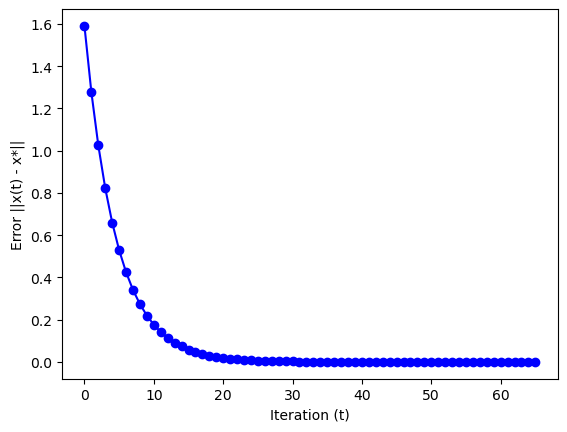

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
A = np.array([[8, 4, 1, 2], [4, 10, 1, 3], [1, 1, 4, 1], [2, 3, 1, 8]])
D = np.diag([8, 10, 4, 8])
b = np.array([15, 18, 7, 14])
D_inv = np.linalg.inv(D)

# Actual solution x*
x_star = np.linalg.solve(A, b)

# Run iteration
x_t = np.zeros(4)  # Initial point
iter_max = 10**6
error_bound = 10**-6
errors = []

converged = False

for t in range(1, iter_max + 1):
    x_t = D_inv @ (D - A) @ x_t + D_inv @ b
    error = np.linalg.norm(x_t - x_star)
    errors.append(error)

    if error <= error_bound:
        converged = True
        break

# Print results
if converged:
    print("Converged at iteration:", t)
    print("Final x(t) is", x_t)
    print("True x* is", x_star)
else:
    print("Did not converge within the iteration limit.")

# Plotting
if converged:
    plt.plot(errors[:100], 'o-', color='blue')
    plt.xlabel('Iteration (t)')
    plt.ylabel('Error ||x(t) - x*||')
else:
    plt.plot(errors, 'o-', color='blue')
    plt.xlabel('Iteration (t)')
    plt.ylabel('Error ||x(t) - x*||')

plt.show()